# Banking Application Logout Feedback Analysis

This notebook provides comprehensive analysis of user feedback for banking applications (Collections, Payments, and Customer Service Center) with focus on logout experience.

**Analysis Includes:**
- Synthetic dataset generation with 500+ realistic feedback records
- Statistical analysis and rating distributions
- Sentiment analysis of feedback text
- Text analysis and keyword extraction
- Visualizations and insights
- Actionable recommendations


## Cell 1: Setup and Imports

In [1]:
import pandas as pd
import numpy as np
import random
from collections import Counter
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import ngrams
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

random.seed(42)
np.random.seed(42)

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print('✓ All imports successful and NLTK data downloaded')


✓ All imports successful and NLTK data downloaded


## Cell 2: Synthetic Dataset Generation

In [2]:
feedback_5_star = {
    'Collections': [
        'Excellent logout process! Payment confirmation was instant and clear.',
        'Very smooth experience. Quick logout and immediate receipt download.',
        'Outstanding! Session ended securely without any hassle.'
    ],
    'Payments': [
        'Fantastic! Transaction status was instant and logout was smooth.',
        'Excellent security and quick logout process.',
        'Very impressed! Fast transaction processing and secure logout.'
    ],
    'Customer Service Center': [
        'Excellent support! Chat history saved perfectly before logout.',
        'Outstanding! Ticket status remained intact after logout.',
        'Perfect experience! All support tickets visible and logout smooth.'
    ]
}

feedback_4_star = {
    'Collections': [
        'Good logout experience. Payment confirmation took a moment to appear.',
        'Very good! Receipt download works well after logout.',
        'Satisfied! Logout process is quick and secure.'
    ],
    'Payments': [
        'Good! Transaction status visible but could update faster.',
        'Very good security features and reasonable logout speed.',
        'Satisfied with the transaction processing.'
    ],
    'Customer Service Center': [
        'Good! Chat history saved but took a moment to load.',
        'Satisfied! Ticket status preserved after logout.',
        'Very good support experience overall.'
    ]
}

feedback_3_star = {
    'Collections': [
        'Average logout experience. Sometimes slow, sometimes fast.',
        'Okay. Payment confirmation works but could be faster.',
        'Acceptable. Nothing special but no major issues.'
    ],
    'Payments': [
        'Average! Transaction updates could be faster.',
        'Okay experience. Security is good, speed could improve.',
        'Fair! Works most of the time but occasional hiccups.'
    ],
    'Customer Service Center': [
        'Average support experience. Response times could be better.',
        'Okay! Chat history works but loading is slow.',
        'Fair experience. Support quality is standard.'
    ]
}

feedback_2_star = {
    'Collections': [
        'Frustrated! Payment confirmation never appeared after logout.',
        'Poor experience. Receipt download is extremely slow.',
        'Disappointed! Session timed out before payment confirmation.'
    ],
    'Payments': [
        'Poor! Transaction status does not update after logout.',
        'Frustrated! Security verification takes too long.',
        'Bad experience. Transaction processing is slow.'
    ],
    'Customer Service Center': [
        'Poor! Chat history lost after logout.',
        'Frustrated! Ticket status not preserved after logout.',
        'Bad experience. Support staff unhelpful.'
    ]
}

feedback_1_star = {
    'Collections': [
        'Terrible! Lost payment confirmation after logout. Very concerning.',
        'Awful experience! Cannot retrieve receipt after session ends.',
        'Extremely frustrated! Payment status vanished after logout.'
    ],
    'Payments': [
        'Terrible! Transaction completely disappeared after logout.',
        'Awful! Security verification failed during logout.',
        'Worst experience! Cannot verify payment after logout.'
    ],
    'Customer Service Center': [
        'Terrible! Entire chat history deleted after logout.',
        'Awful! Cannot access ticket after logout.',
        'Worst support experience ever!'
    ]
}

feedback_templates = {5: feedback_5_star, 4: feedback_4_star, 3: feedback_3_star, 2: feedback_2_star, 1: feedback_1_star}
applications = ['Collections', 'Payments', 'Customer Service Center']

records = []
rating_distribution = {5: 0.30, 4: 0.35, 3: 0.20, 2: 0.10, 1: 0.05}
total_records = 570
records_per_app = total_records // 3

for app in applications:
    for rating in [5, 4, 3, 2, 1]:
        count = int(records_per_app * rating_distribution[rating])
        feedback_list = feedback_templates[rating][app]
        for _ in range(count):
            feedback = random.choice(feedback_list)
            records.append({'application_name': app, 'rating': rating, 'feedback': feedback})

df = pd.DataFrame(records)
df = df.sample(frac=1).reset_index(drop=True)

print(f'✓ Dataset generated successfully!')
print(f'Total records: {len(df)}')
print(f'Records per application: {len(df) // 3}')


✓ Dataset generated successfully!
Total records: 567
Records per application: 189


## Cell 3: Data Overview

In [3]:
print('='*80)
print('DATASET OVERVIEW')
print('='*80)
print(f'Dataset Shape: {df.shape}')
print(f'First 5 records:')
print(df.head())
print(f'Data Types:')
print(df.dtypes)
print(f'Missing Values:')
print(df.isnull().sum())
print(f'Basic Statistics - Rating:')
print(df['rating'].describe())
print(f'Application Distribution:')
print(df['application_name'].value_counts())
print(f'Rating Distribution:')
print(df['rating'].value_counts().sort_index(ascending=False))


DATASET OVERVIEW
Dataset Shape: (567, 3)
First 5 records:
          application_name  rating  \
0  Customer Service Center       2   
1  Customer Service Center       3   
2                 Payments       5   
3  Customer Service Center       3   
4  Customer Service Center       4   

                                            feedback  
0           Bad experience. Support staff unhelpful.  
1      Okay! Chat history works but loading is slow.  
2  Fantastic! Transaction status was instant and ...  
3  Average support experience. Response times cou...  
4  Good! Chat history saved but took a moment to ...  
Data Types:
application_name    object
rating               int64
feedback            object
dtype: object
Missing Values:
application_name    0
rating              0
feedback            0
dtype: int64
Basic Statistics - Rating:
count    567.000000
mean       3.756614
std        1.129756
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max        5.0

## Cell 4: Rating Distribution Analysis

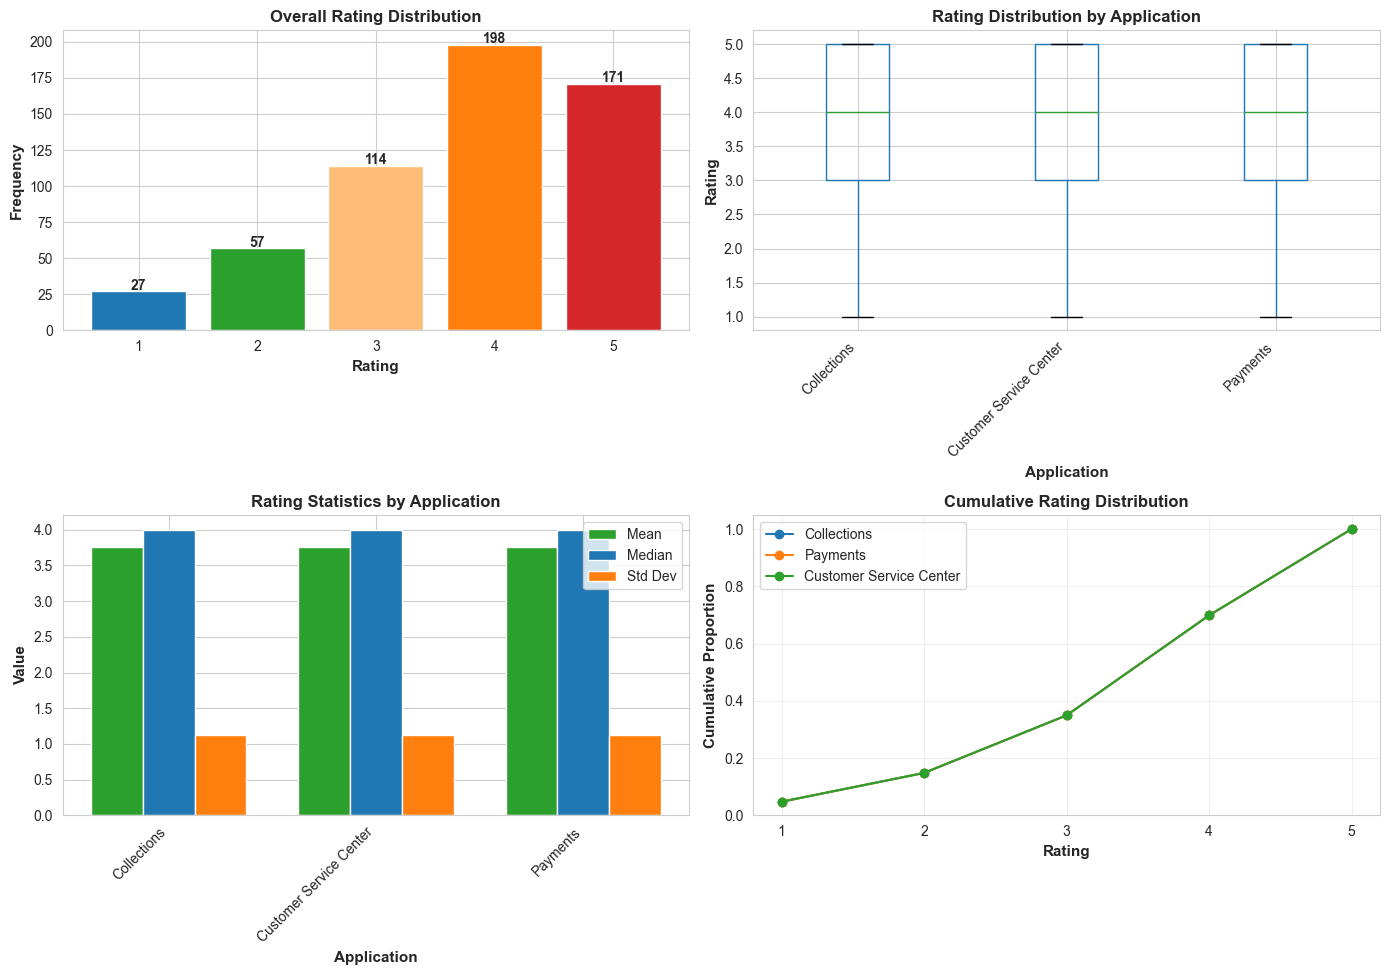

RATING STATISTICS BY APPLICATION
                         count  mean   std  min  25%  50%  75%  max
application_name                                                   
Collections              189.0  3.76  1.13  1.0  3.0  4.0  5.0  5.0
Customer Service Center  189.0  3.76  1.13  1.0  3.0  4.0  5.0  5.0
Payments                 189.0  3.76  1.13  1.0  3.0  4.0  5.0  5.0


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax1 = axes[0, 0]
rating_counts = df['rating'].value_counts().sort_index()
colors = ['#d62728', '#ff7f0e', '#ffbb78', '#2ca02c', '#1f77b4']
ax1.bar(rating_counts.index, rating_counts.values, color=colors[::-1])
ax1.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax1.set_title('Overall Rating Distribution', fontsize=12, fontweight='bold')
ax1.set_xticks([1, 2, 3, 4, 5])
for i, v in enumerate(rating_counts.values):
    ax1.text(rating_counts.index[i], v + 1, str(v), ha='center', fontweight='bold')

ax2 = axes[0, 1]
df.boxplot(column='rating', by='application_name', ax=ax2)
ax2.set_xlabel('Application', fontsize=11, fontweight='bold')
ax2.set_ylabel('Rating', fontsize=11, fontweight='bold')
ax2.set_title('Rating Distribution by Application', fontsize=12, fontweight='bold')
plt.sca(ax2)
plt.xticks(rotation=45, ha='right')
ax2.get_figure().suptitle('')

ax3 = axes[1, 0]
app_stats = df.groupby('application_name')['rating'].agg(['mean', 'median', 'std'])
x = np.arange(len(app_stats.index))
width = 0.25
ax3.bar(x - width, app_stats['mean'], width, label='Mean', color='#2ca02c')
ax3.bar(x, app_stats['median'], width, label='Median', color='#1f77b4')
ax3.bar(x + width, app_stats['std'], width, label='Std Dev', color='#ff7f0e')
ax3.set_xlabel('Application', fontsize=11, fontweight='bold')
ax3.set_ylabel('Value', fontsize=11, fontweight='bold')
ax3.set_title('Rating Statistics by Application', fontsize=12, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(app_stats.index, rotation=45, ha='right')
ax3.legend()

ax4 = axes[1, 1]
for app in applications:
    app_data = df[df['application_name'] == app]['rating'].value_counts().sort_index()
    cumsum = app_data.cumsum() / len(df[df['application_name'] == app])
    ax4.plot(cumsum.index, cumsum.values, marker='o', label=app)
ax4.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax4.set_ylabel('Cumulative Proportion', fontsize=11, fontweight='bold')
ax4.set_title('Cumulative Rating Distribution', fontsize=12, fontweight='bold')
ax4.set_xticks([1, 2, 3, 4, 5])
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('RATING STATISTICS BY APPLICATION')
print(df.groupby('application_name')['rating'].describe().round(2))


## Cell 5: Sentiment Analysis

In [5]:
sia = SentimentIntensityAnalyzer()
print('Calculating sentiment scores...')

df['sentiment_textblob'] = df['feedback'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['sentiment_vader'] = df['feedback'].apply(lambda x: sia.polarity_scores(x)['compound'])
df['sentiment_score'] = (df['sentiment_textblob'] + df['sentiment_vader']) / 2

def categorize_sentiment(score):
    if score >= 0.3:
        return 'Positive'
    elif score <= -0.3:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_category'] = df['sentiment_score'].apply(categorize_sentiment)

print('✓ Sentiment scores calculated successfully!')
print(f'Sentiment Score Statistics:')
print(df['sentiment_score'].describe().round(3))
print(f'Sentiment Category Distribution:')
print(df['sentiment_category'].value_counts())


Calculating sentiment scores...
✓ Sentiment scores calculated successfully!
Sentiment Score Statistics:
count    567.000
mean       0.368
std        0.459
min       -0.829
25%        0.246
50%        0.566
75%        0.642
max        0.964
Name: sentiment_score, dtype: float64
Sentiment Category Distribution:
sentiment_category
Positive    412
Negative     84
Neutral      71
Name: count, dtype: int64


## Cell 6: Sentiment Distribution & Visualization

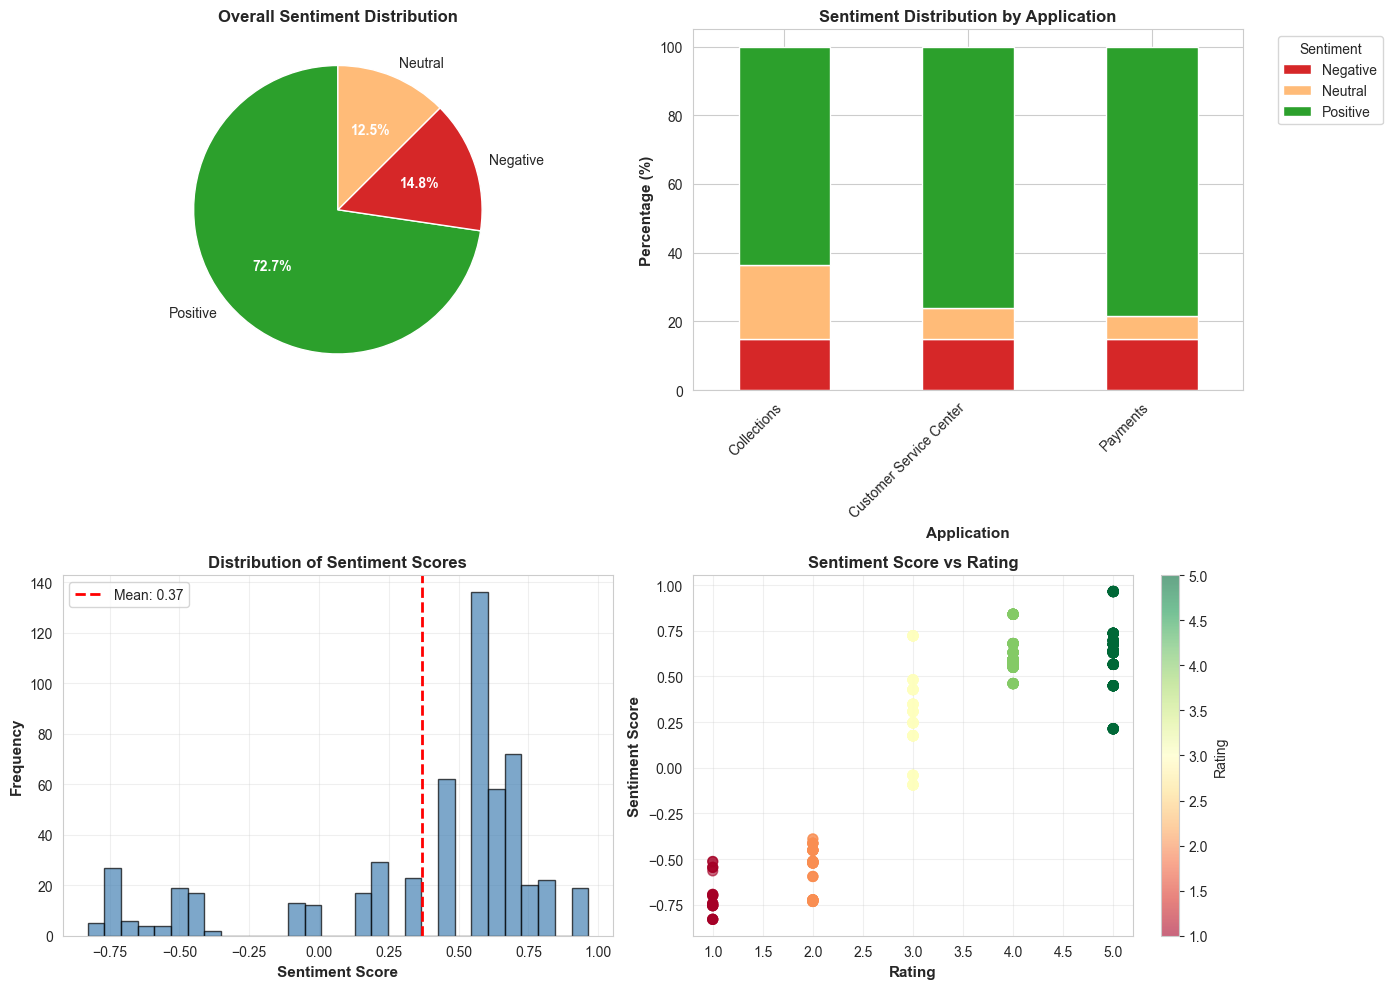

SENTIMENT BY APPLICATION:
sentiment_category       Negative  Neutral  Positive
application_name                                    
Collections                    28       41       120
Customer Service Center        28       17       144
Payments                       28       13       148


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax1 = axes[0, 0]
sentiment_counts = df['sentiment_category'].value_counts()
colors_sentiment = {'Positive': '#2ca02c', 'Neutral': '#ffbb78', 'Negative': '#d62728'}
colors = [colors_sentiment[cat] for cat in sentiment_counts.index]
wedges, texts, autotexts = ax1.pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%', colors=colors, startangle=90)
ax1.set_title('Overall Sentiment Distribution', fontsize=12, fontweight='bold')
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

ax2 = axes[0, 1]
sentiment_by_app = pd.crosstab(df['application_name'], df['sentiment_category'], normalize='index') * 100
sentiment_by_app.plot(kind='bar', stacked=True, ax=ax2, color=['#d62728', '#ffbb78', '#2ca02c'])
ax2.set_title('Sentiment Distribution by Application', fontsize=12, fontweight='bold')
ax2.set_ylabel('Percentage (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Application', fontsize=11, fontweight='bold')
ax2.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

ax3 = axes[1, 0]
ax3.hist(df['sentiment_score'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
ax3.axvline(df['sentiment_score'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["sentiment_score"].mean():.2f}')
ax3.set_xlabel('Sentiment Score', fontsize=11, fontweight='bold')
ax3.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax3.set_title('Distribution of Sentiment Scores', fontsize=12, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
scatter = ax4.scatter(df['rating'], df['sentiment_score'], alpha=0.6, s=50, c=df['rating'], cmap='RdYlGn')
ax4.set_xlabel('Rating', fontsize=11, fontweight='bold')
ax4.set_ylabel('Sentiment Score', fontsize=11, fontweight='bold')
ax4.set_title('Sentiment Score vs Rating', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax4, label='Rating')

plt.tight_layout()
plt.show()

print('SENTIMENT BY APPLICATION:')
print(pd.crosstab(df['application_name'], df['sentiment_category']))


## Cell 7: Text Analysis & Keywords

Extracting keywords...
TOP 20 KEYWORDS ACROSS ALL FEEDBACK
logout               : 313 occurrences
experience           : 156 occurrences
good                 : 151 occurrences
transaction          : 121 occurrences
status               : 106 occurrences
support              :  94 occurrences
payment              :  81 occurrences
could                :  79 occurrences
confirmation         :  72 occurrences
chat                 :  69 occurrences
history              :  69 occurrences
works                :  62 occurrences
process              :  61 occurrences
satisfied            :  60 occurrences
smooth               :  57 occurrences
excellent            :  57 occurrences
faster               :  53 occurrences
security             :  51 occurrences
quick                :  51 occurrences
visible              :  49 occurrences


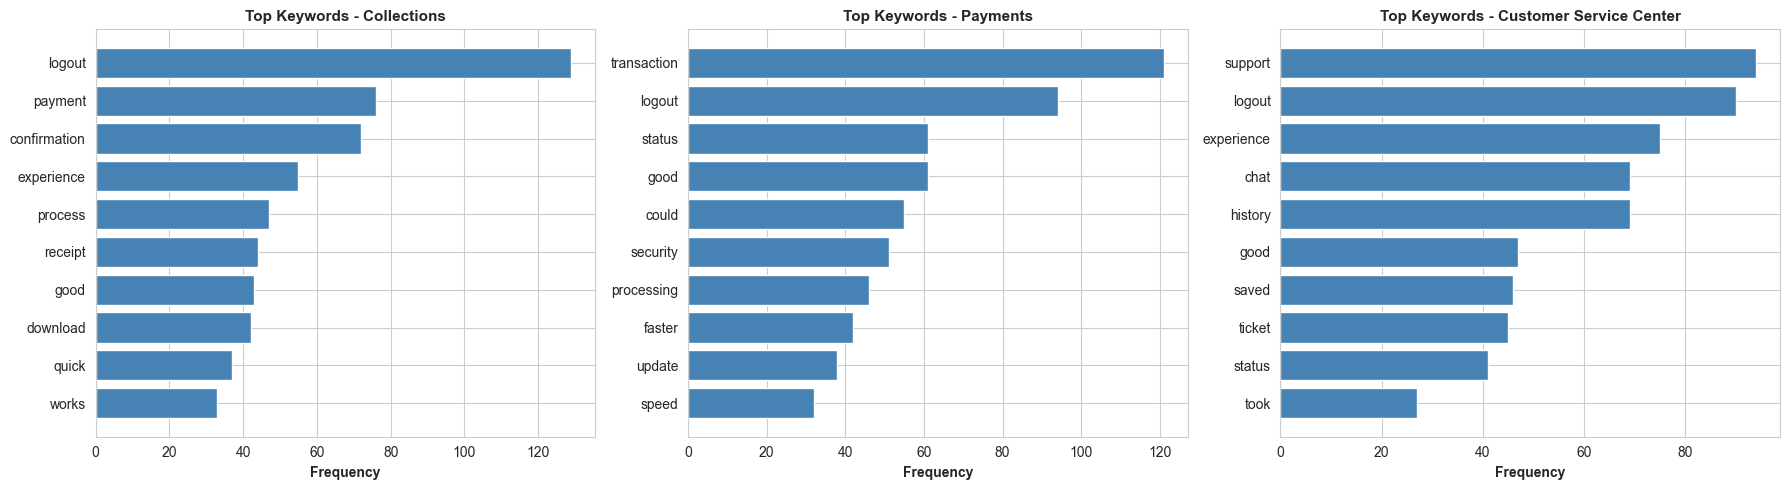

In [7]:
stop_words = set(stopwords.words('english'))

def extract_keywords(text):
    words = word_tokenize(text.lower())
    keywords = [word for word in words if word.isalpha() and word not in stop_words and len(word) > 3]
    return keywords

print('Extracting keywords...')
all_keywords = []
for feedback in df['feedback']:
    all_keywords.extend(extract_keywords(feedback))

keyword_freq = Counter(all_keywords)
top_keywords = dict(keyword_freq.most_common(20))

print('TOP 20 KEYWORDS ACROSS ALL FEEDBACK')
print('='*50)
for keyword, count in top_keywords.items():
    print(f'{keyword:20} : {count:3d} occurrences')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, app in enumerate(applications):
    app_keywords = []
    for feedback in df[df['application_name'] == app]['feedback']:
        app_keywords.extend(extract_keywords(feedback))
    
    app_keyword_freq = Counter(app_keywords)
    top_app_keywords = dict(app_keyword_freq.most_common(10))
    
    ax = axes[idx]
    keywords_list = list(top_app_keywords.keys())
    counts_list = list(top_app_keywords.values())
    ax.barh(keywords_list, counts_list, color='steelblue')
    ax.set_xlabel('Frequency', fontsize=10, fontweight='bold')
    ax.set_title(f'Top Keywords - {app}', fontsize=11, fontweight='bold')
    ax.invert_yaxis()

plt.tight_layout()
plt.show()


## Cell 8: Word Clouds

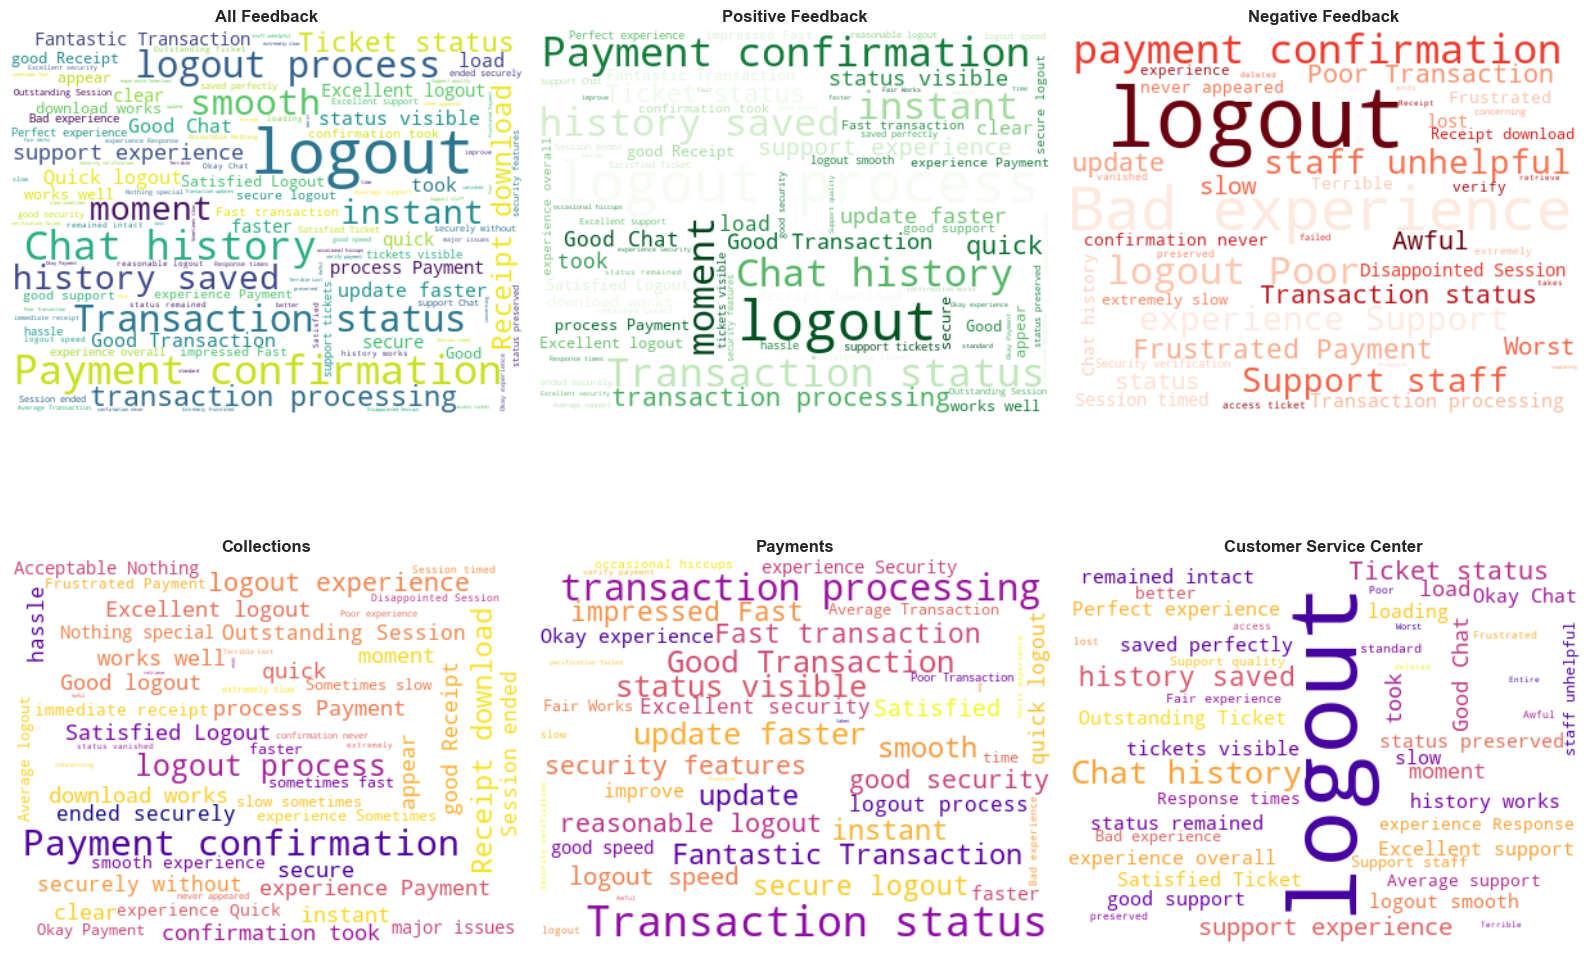

✓ Word clouds generated successfully!


In [8]:
fig = plt.figure(figsize=(16, 12))

ax1 = plt.subplot(2, 3, 1)
all_feedback = ' '.join(df['feedback'].values)
wc_all = WordCloud(width=400, height=300, background_color='white', colormap='viridis').generate(all_feedback)
ax1.imshow(wc_all, interpolation='bilinear')
ax1.set_title('All Feedback', fontsize=12, fontweight='bold')
ax1.axis('off')

ax2 = plt.subplot(2, 3, 2)
positive_feedback = ' '.join(df[df['sentiment_category'] == 'Positive']['feedback'].values)
wc_positive = WordCloud(width=400, height=300, background_color='white', colormap='Greens').generate(positive_feedback)
ax2.imshow(wc_positive, interpolation='bilinear')
ax2.set_title('Positive Feedback', fontsize=12, fontweight='bold')
ax2.axis('off')

ax3 = plt.subplot(2, 3, 3)
negative_feedback = ' '.join(df[df['sentiment_category'] == 'Negative']['feedback'].values)
wc_negative = WordCloud(width=400, height=300, background_color='white', colormap='Reds').generate(negative_feedback)
ax3.imshow(wc_negative, interpolation='bilinear')
ax3.set_title('Negative Feedback', fontsize=12, fontweight='bold')
ax3.axis('off')

for idx, app in enumerate(applications):
    ax = plt.subplot(2, 3, idx + 4)
    app_feedback = ' '.join(df[df['application_name'] == app]['feedback'].values)
    wc_app = WordCloud(width=400, height=300, background_color='white', colormap='plasma').generate(app_feedback)
    ax.imshow(wc_app, interpolation='bilinear')
    ax.set_title(app, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()
print('✓ Word clouds generated successfully!')


## Cell 9: Issue Identification & Summary

ISSUE IDENTIFICATION & SATISFACTION DRIVERS
Low-Rated Feedback (1-2 stars) - Count: 84
Collections: 28 issues
Payments: 28 issues
Customer Service Center: 28 issues

High-Rated Feedback (4-5 stars) - Count: 369
Collections: 123 satisfied users
Payments: 123 satisfied users
Customer Service Center: 123 satisfied users


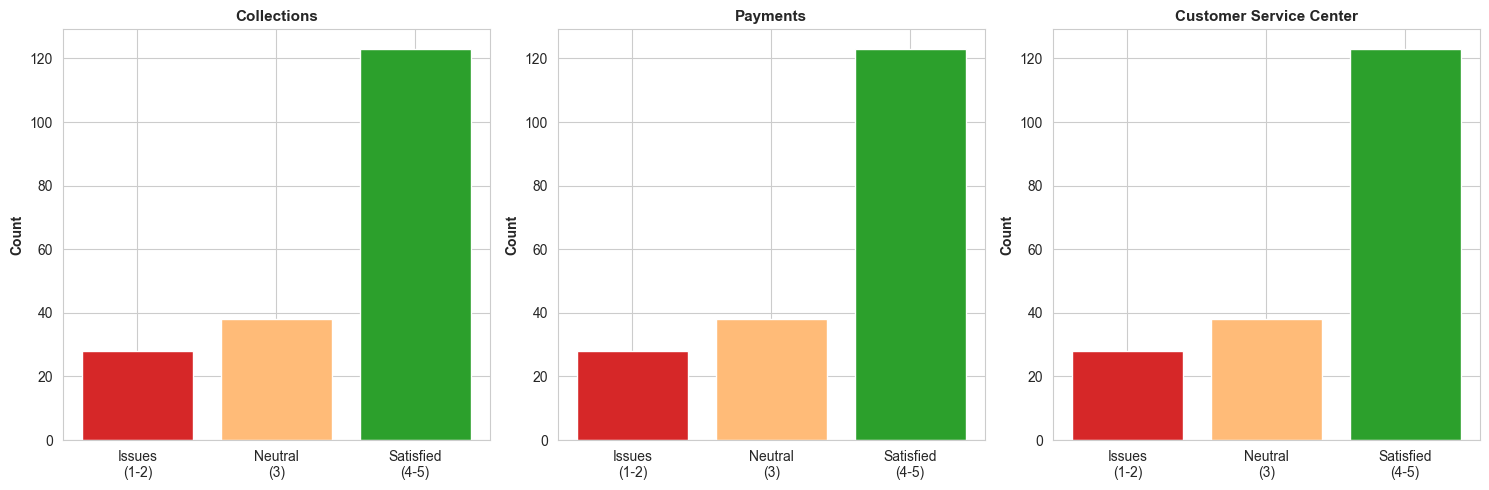

In [9]:
print('='*80)
print('ISSUE IDENTIFICATION & SATISFACTION DRIVERS')
print('='*80)

low_rated = df[df['rating'] <= 2][['application_name', 'rating', 'feedback']]
print(f'Low-Rated Feedback (1-2 stars) - Count: {len(low_rated)}')

for app in applications:
    app_issues = low_rated[low_rated['application_name'] == app]
    print(f'{app}: {len(app_issues)} issues')

high_rated = df[df['rating'] >= 4][['application_name', 'rating', 'feedback']]
print(f'\nHigh-Rated Feedback (4-5 stars) - Count: {len(high_rated)}')

for app in applications:
    app_drivers = high_rated[high_rated['application_name'] == app]
    print(f'{app}: {len(app_drivers)} satisfied users')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, app in enumerate(applications):
    ax = axes[idx]
    app_data = df[df['application_name'] == app]
    
    issue_count = len(app_data[app_data['rating'] <= 2])
    neutral_count = len(app_data[(app_data['rating'] == 3)])
    satisfied_count = len(app_data[app_data['rating'] >= 4])
    
    categories = ['Issues\n(1-2)', 'Neutral\n(3)', 'Satisfied\n(4-5)']
    values = [issue_count, neutral_count, satisfied_count]
    colors_cat = ['#d62728', '#ffbb78', '#2ca02c']
    
    bars = ax.bar(categories, values, color=colors_cat)
    ax.set_ylabel('Count', fontsize=10, fontweight='bold')
    ax.set_title(app, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


## Cell 10: Executive Summary & KPIs

In [10]:
print('\n' + '='*80)
print('EXECUTIVE SUMMARY - BANKING APPLICATION LOGOUT FEEDBACK ANALYSIS')
print('='*80)

overall_satisfaction = len(df[df['rating'] >= 4]) / len(df) * 100
overall_issues = len(df[df['rating'] <= 2]) / len(df) * 100
overall_avg_rating = df['rating'].mean()
overall_avg_sentiment = df['sentiment_score'].mean()
correlation = df['rating'].corr(df['sentiment_score'])

print(f'Total Records Analyzed: {len(df)}')
print(f'Overall Average Rating: {overall_avg_rating:.2f} / 5.00')
print(f'Overall Average Sentiment: {overall_avg_sentiment:.3f}')
print(f'Customer Satisfaction Rate (4-5 stars): {overall_satisfaction:.1f}%')
print(f'Issue Rate (1-2 stars): {overall_issues:.1f}%')
print(f'Positive Sentiment: {(len(df[df["sentiment_category"] == "Positive"]) / len(df) * 100):.1f}%')
print(f'Negative Sentiment: {(len(df[df["sentiment_category"] == "Negative"]) / len(df) * 100):.1f}%')
print(f'Rating-Sentiment Correlation: {correlation:.3f}')

print(f'\nAPPLICATION PERFORMANCE:')
print('='*80)

for app in sorted(applications, key=lambda x: df[df['application_name']==x]['rating'].mean(), reverse=True):
    app_data = df[df['application_name'] == app]
    rating = app_data['rating'].mean()
    satisfaction = len(app_data[app_data['rating'] >= 4]) / len(app_data) * 100
    sentiment = app_data['sentiment_score'].mean()
    print(f'{app:30} | Rating: {rating:.2f}/5 | Satisfaction: {satisfaction:.1f}% | Sentiment: {sentiment:.3f}')

print(f'\nKEY FINDINGS:')
print('='*80)
print(f'1. Overall customer satisfaction is at {overall_satisfaction:.1f}%')
print(f'2. {overall_issues:.1f}% of users reported issues (1-2 stars)')
print(f'3. Sentiment analysis shows {(len(df[df["sentiment_category"] == "Positive"]) / len(df) * 100):.1f}% positive feedback')
print(f'4. Rating-sentiment correlation is {correlation:.3f} (strong alignment)')

print(f'\nRECOMMENDATIONS:')
print('='*80)
if overall_avg_rating >= 3.8:
    print('✓ Good performance. Maintain quality and monitor for improvements.')
elif overall_avg_rating >= 3.2:
    print('⚠ Fair performance. Address identified issues within 2-4 weeks.')
else:
    print('✗ Critical issues. Implement immediate action plan.')

print(f'\nReport Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
print('='*80)



EXECUTIVE SUMMARY - BANKING APPLICATION LOGOUT FEEDBACK ANALYSIS
Total Records Analyzed: 567
Overall Average Rating: 3.76 / 5.00
Overall Average Sentiment: 0.368
Customer Satisfaction Rate (4-5 stars): 65.1%
Issue Rate (1-2 stars): 14.8%
Positive Sentiment: 72.7%
Negative Sentiment: 14.8%
Rating-Sentiment Correlation: 0.841

APPLICATION PERFORMANCE:
Collections                    | Rating: 3.76/5 | Satisfaction: 65.1% | Sentiment: 0.321
Payments                       | Rating: 3.76/5 | Satisfaction: 65.1% | Sentiment: 0.350
Customer Service Center        | Rating: 3.76/5 | Satisfaction: 65.1% | Sentiment: 0.433

KEY FINDINGS:
1. Overall customer satisfaction is at 65.1%
2. 14.8% of users reported issues (1-2 stars)
3. Sentiment analysis shows 72.7% positive feedback
4. Rating-sentiment correlation is 0.841 (strong alignment)

RECOMMENDATIONS:
⚠ Fair performance. Address identified issues within 2-4 weeks.

Report Generated: 2026-01-10 12:17:46


## Cell 11: Data Export

In [11]:
df_export = df[['application_name', 'rating', 'feedback', 'sentiment_score', 'sentiment_category']].copy()
df_export.to_csv('feedback_analysis_with_sentiment.csv', index=False)
print('✓ Processed dataset exported to feedback_analysis_with_sentiment.csv')

summary_stats = {
    'Metric': ['Total Records', 'Average Rating', 'Average Sentiment', 'Satisfaction Rate', 'Issue Rate'],
    'Value': [len(df), f'{df["rating"].mean():.2f}', f'{df["sentiment_score"].mean():.3f}', 
              f'{(len(df[df["rating"] >= 4]) / len(df) * 100):.1f}%', f'{overall_issues:.1f}%']
}

summary_df = pd.DataFrame(summary_stats)
summary_df.to_csv('summary_statistics.csv', index=False)
print('✓ Summary statistics exported to summary_statistics.csv')

print(f'\n✓ All exports completed successfully!')


✓ Processed dataset exported to feedback_analysis_with_sentiment.csv
✓ Summary statistics exported to summary_statistics.csv

✓ All exports completed successfully!
